# 二型中心裂纹：外部基本解 + KM–Williams 复势富集

沿用一型参考代码的外部源点、列归一化、SVD 初始化和最优损失恢复机制。裂尖周围**不设置任何局部源点**；奇异场由 $p=1/2$ 的复势描述，$p=3/2,5/2$ 表示高阶场。最后一个物理系数就是 $K_{II}$。

保持原始几何 $a=1,b=2,h=6$、四边纯剪切载荷和二型四分之一模型边界条件。参考公式只用于求解后的误差评价，绝不进入训练或参数选择。

在本次 NumPy/SciPy 实测中，正确符号得到 $K_{II}\approx2.1317503$，原参考公式为 $2.1025452$，差异约 **1.389%**。源点数 48/64/80 的结果稳定在约 2.13176，故不能将该差异简单归因于优化不足，也不能保证参考式与该边值问题严格等价。要宣称更高精度，需要同几何、同载荷的独立 FEM/BEM 验证。

复数基函数固定在 CPU 上计算；有 PyTorch 时，实矩阵系数通过 Adam/L-BFGS 训练；没有 PyTorch 时，明确使用同一目标的 SVD 求解，不声称执行了神经网络训练。默认仅显示结果和图，不保存绘图文件。

In [1]:
import math
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lstsq as scipy_lstsq
try:
    import torch
except ImportError:
    torch = None

cfg = {
    "a": 1.0, "b": 2.0, "h": 6.0,
    "E": 1.0, "nu": 0.30, "tau0": 1.0, "plane_strain": True,
    "n_top": 121, "n_side": 121, "n_crack": 100, "n_ligament": 100,
    "eps_crack": 1.0e-6,
    "n_src_side": 64, "src_margin_x_factor": 0.15,
    "src_margin_y_factor": 0.05,
    "higher_williams_orders": [1.5, 2.5],
    "ls_warm_start": True, "svd_rcond": 1.0e-12,
    "lambda_reg": 1.0e-10,
    "adam_steps": 500, "adam_lr": 1.0e-3,
    "lbfgs_epochs": 50, "lbfgs_max_iter": 20,
    "w_top": 2.5, "w_right": 1.5, "w_left": 4.0,
    "w_crack": 4.0, "w_ligament": 4.0,
    "nx_plot": 141, "ny_plot": 141, "seed": 2026,
    "compare_uy_signs": True,
    "save_outputs": False, "output_dir": "mode_ii_results",
}
a, b, h = (float(cfg[k]) for k in ("a", "b", "h"))
E, nu, tau0 = (float(cfg[k]) for k in ("E", "nu", "tau0"))
assert 0 < a < b and h > 0 and E > 0 and -1 < nu < 0.5
mu = E / (2 * (1 + nu))
kappa = 3 - 4*nu if cfg["plane_strain"] else (3-nu)/(1+nu)
lam = E*nu/((1+nu)*(1-2*nu)) if cfg["plane_strain"] else E*nu/(1-nu**2)
np.random.seed(cfg["seed"])
if torch is not None:
    torch.set_default_dtype(torch.float64)
    torch.manual_seed(cfg["seed"])
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
else:
    device = "cpu"
print("Basis: CPU NumPy float64/complex128")
print("Training:", device if torch is not None else "PyTorch unavailable; SciPy SVD only")

def reference_kii_tada(a_value=a, b_value=b, shear=tau0):
    ratio = a_value / b_value
    return shear * np.sqrt(np.pi*a_value) * (1-0.025*ratio**2+0.06*ratio**4) / np.sqrt(np.cos(np.pi*ratio/2))

# This benchmark approximation is evaluation-only.
KII_REF = float(reference_kii_tada())

def maybe_savefig(fig, filename):
    if cfg["save_outputs"]:
        folder = Path(cfg["output_dir"])
        folder.mkdir(parents=True, exist_ok=True)
        fig.savefig(folder / filename, dpi=600, bbox_inches="tight")

Basis: CPU NumPy float64/complex128
Training: cuda


## 几何与源点
只保留人工矩形边界上的外部源点。上边与右边均施加 $\sigma_{xy}=\tau_0$；左边采用 $u_y=0,\sigma_{xx}=0$；韧带采用 $u_x=0,\sigma_{yy}=0$，裂面无牵引。

Exterior sources: 252; local crack-tip sources: 0


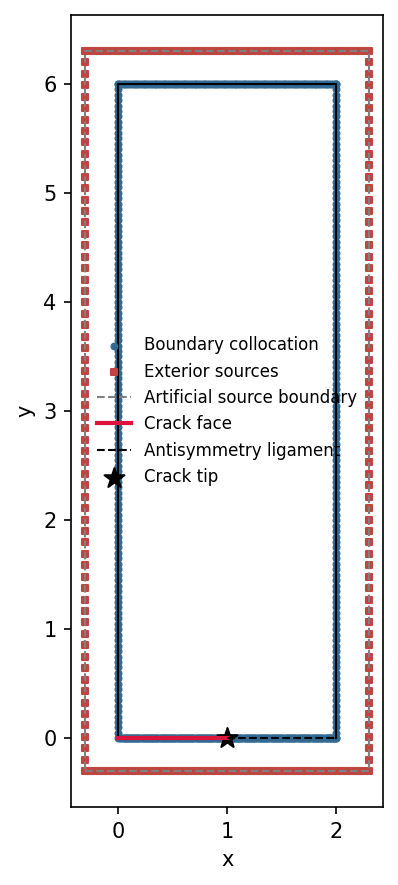

In [2]:
def generate_boundary_points(counts=None, midpoint=False):
    counts = cfg if counts is None else counts
    def line(lo, hi, n):
        if midpoint:
            return lo + (np.arange(n)+0.5)*(hi-lo)/n
        return np.linspace(lo, hi, n)
    return {
        "top": line(0, b, counts["n_top"]) + 1j*h,
        "right": b + 1j*line(0, h, counts["n_side"]),
        "left": 1j*line(0, h, counts["n_side"]),
        "crack": line(0.02*a, 0.98*a, counts["n_crack"]) + 1j*cfg["eps_crack"],
        "ligament": line(1.02*a, b, counts["n_ligament"]) + 0j,
    }

def generate_source_points(n=None):
    n = cfg["n_src_side"] if n is None else int(n)
    mx, my = cfg["src_margin_x_factor"]*b, cfg["src_margin_y_factor"]*h
    if n < 2 or min(mx, my) <= 0:
        raise ValueError("Require n>=2 and positive exterior source margins")
    xs, ys = np.linspace(-mx, b+mx, n), np.linspace(-my, h+my, n)
    sources = np.r_[xs-1j*my, xs+1j*(h+my),
                    -mx+1j*ys[1:-1], b+mx+1j*ys[1:-1]]
    assert np.all((sources.real < 0) | (sources.real > b) |
                  (sources.imag < 0) | (sources.imag > h))
    return sources

bnd_pts = generate_boundary_points()
src_pts = generate_source_points()
print(f"Exterior sources: {len(src_pts)}; local crack-tip sources: 0")
fig, ax = plt.subplots(figsize=(5.5, 6), dpi=150)
for i, (name, z) in enumerate(bnd_pts.items()):
    ax.scatter(z.real, z.imag, s=8, color="#326A93",
               label="Boundary collocation" if i == 0 else None)
ax.scatter(src_pts.real, src_pts.imag, s=9, marker="s", color="#BE4540", label="Exterior sources")
mx, my = cfg["src_margin_x_factor"]*b, cfg["src_margin_y_factor"]*h
ax.plot([-mx,b+mx,b+mx,-mx,-mx],[-my,-my,h+my,h+my,-my],"--",color="gray",lw=1,label="Artificial source boundary")
ax.plot([0,0,b,b],[0,h,h,0],"k-",lw=1)
ax.plot([0,a],[0,0],color="crimson",lw=2,label="Crack face")
ax.plot([a,b],[0,0],"k--",lw=1,label="Antisymmetry ligament")
ax.scatter([a],[0],s=100,marker="*",color="black",label="Crack tip")
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend(fontsize=8,frameon=False); fig.tight_layout()
maybe_savefig(fig, "sources.png"); plt.show()

## KM 复势与二型 Williams 富集
令 $z=x+iy,w=z-a,p=n/2$。采用
\[
\phi_p=-\frac{i}{\sqrt{2\pi}}h^{1/2-p}w^p,\qquad
\psi_p=-(p+1)\phi_p-a\phi'_p.
\]
其中平移修正 $-a\phi'_p$ 不可省略；$p=1/2$ 的系数为 $K_{II}$，高阶系数独立学习。

在当前 $u_x+iu_y$、正 $K_{II}$ 对应裂尖前方正 $\sigma_{xy}$ 的约定下，正确位移为
\[
u_y=-\frac{K_{II}}{2\mu}\sqrt{\frac r{2\pi}}\cos\frac\theta2(\kappa-2+\cos\theta).
\]
这表示整个角函数前的负号，不表示所有位置的 $u_y$ 数值必然为负。符号由本构一致性确定，不能只按与参考值的距离来选择。

In [3]:
QUANTITIES = ("ux", "uy", "sxx", "syy", "sxy")

def km_response(z, phi, dphi, ddphi, psi, dpsi):
    stress_sum = 4*dphi.real
    stress_diff = 2*(z.conjugate()*ddphi+dpsi)
    displacement = (kappa*phi-z*dphi.conjugate()-psi.conjugate())/(2*mu)
    return np.column_stack((displacement.real, displacement.imag,
                            (stress_sum-stress_diff.real)/2,
                            (stress_sum+stress_diff.real)/2,
                            stress_diff.imag/2))

def complex_point_force_potential_response(z, source, force):
    q = z-source
    den = 2*np.pi*(kappa+1)
    phi = -force/den*np.log(q) + force/(2*np.pi*kappa*(kappa+1))
    dphi, ddphi = -force/den/q, force/den/q**2
    psi = kappa*force.conjugate()/den*np.log(q) + force*source.conjugate()/den/q
    dpsi = kappa*force.conjugate()/den/q - force*source.conjugate()/den/q**2
    return km_response(z, phi, dphi, ddphi, psi, dpsi)

def mode_ii_williams_response(z, p=0.5):
    if p < 0.5 or abs((p-0.5)-round(p-0.5)) > 1e-12:
        raise ValueError("Use p=0.5, 1.5, 2.5, ...")
    z = np.asarray(z, dtype=np.complex128).reshape(-1)
    w = z-a
    if np.any(np.abs(w) == 0):
        raise ValueError("Do not evaluate exactly at the singular crack tip")
    C = -1j / np.sqrt(2*np.pi) * h**(0.5-p)
    phi, dphi = C*w**p, C*p*w**(p-1)
    ddphi = C*p*(p-1)*w**(p-2)
    psi = -(p+1)*phi-a*dphi
    dpsi = -(p+1)*dphi-a*ddphi
    return km_response(z, phi, dphi, ddphi, psi, dpsi)

def build_basis_columns(points, sources=None, uy_sign=-1):
    # uy_sign=+1 deliberately reproduces the OLD, inconsistent leading uy.
    # This flag is diagnostic only. All physical predictions use uy_sign=-1.
    if uy_sign not in (-1, 1):
        raise ValueError("uy_sign must be -1 or +1")
    z = np.asarray(points, dtype=np.complex128).reshape(-1)
    sources = src_pts if sources is None else sources
    cols = [complex_point_force_potential_response(z,s,P)
            for s in sources for P in (1+0j, 1j)]
    cols += [mode_ii_williams_response(z,p) for p in cfg["higher_williams_orders"]]
    leading = mode_ii_williams_response(z,0.5)
    if uy_sign == 1:
        leading[:,1] *= -1
    cols.append(leading)
    array = np.stack(cols,axis=2)
    assert np.isfinite(array).all()
    return {q: array[:,i,:] for i,q in enumerate(QUANTITIES)}

BOUNDARY_BLOCKS = [
    ("top","syy",0.0,"w_top"), ("top","sxy",tau0,"w_top"),
    ("right","sxx",0.0,"w_right"), ("right","sxy",tau0,"w_right"),
    ("left","uy",0.0,"w_left"), ("left","sxx",0.0,"w_left"),
    ("crack","syy",0.0,"w_crack"), ("crack","sxy",0.0,"w_crack"),
    ("ligament","ux",0.0,"w_ligament"), ("ligament","syy",0.0,"w_ligament"),
]

def assemble_system(points=bnd_pts, sources=None, uy_sign=-1):
    matrices = {g:build_basis_columns(z,sources,uy_sign) for g,z in points.items()}
    rows, rhs = [], []
    for g,q,target,key in BOUNDARY_BLOCKS:
        block = matrices[g][q]
        factor = np.sqrt(cfg[key]/len(block))
        rows.append(factor*block)
        rhs.append(np.full((len(block),1),factor*target))
    A, rhs = np.vstack(rows), np.vstack(rhs)
    scale = np.linalg.norm(A,axis=0)
    scale = np.where(scale>0,scale,1.0)
    return matrices, A/scale, rhs, scale

basis, A, rhs, col_scale = assemble_system()
n_unknowns = A.shape[1]

def solve_same_objective_ls(A_value=A, rhs_value=rhs):
    n = A_value.shape[1]
    if cfg["lambda_reg"] > 0:
        R = np.eye(n)[:-1]*np.sqrt(cfg["lambda_reg"]/(n-1))
        augmented = np.vstack((A_value,R))
        target = np.vstack((rhs_value,np.zeros((n-1,1))))
    else:
        augmented, target = A_value, rhs_value
    theta,_,rank,s = scipy_lstsq(augmented,target,
                               cond=cfg["svd_rcond"],lapack_driver="gelsd")
    info = {"rank":int(rank),"unknowns":n,
            "objective":float(np.sum((augmented@theta-target)**2))}
    return theta,info

def numpy_objective(theta):
    return float(np.sum((A@theta-rhs)**2)+cfg["lambda_reg"]*np.mean(theta[:-1]**2))

theta_ls, ls_info = solve_same_objective_ls()
print(f"Equations / unknowns: {A.shape}; augmented SVD rank: {ls_info['rank']}")
print(f"SVD boundary-only KII={float(theta_ls[-1,0]/col_scale[-1]):.10f}")

Equations / unknowns: (1126, 507); augmented SVD rank: 507
SVD boundary-only KII=2.1317503253


## 符号对照与本构验证
两种符号均求解同一边界最小二乘问题。对照项只改变原代码有争议的首阶 $u_y$，其余相同。高阶项一直由正确复势生成。额外在域内检查位移导数生成的 Hooke 应力是否与基函数应力相符；这比单看参考误差更能判断符号是否正确。

In [4]:
def tip_constitutive_error(uy_sign):
    z = np.array([a+0.3+0.2j, a-0.2+0.3j, a+0.6+0.4j])
    def field(zz):
        out = mode_ii_williams_response(zz,0.5)
        if uy_sign == 1: out[:,1] *= -1
        return out
    delta = 1e-6*a
    dx = (field(z+delta)-field(z-delta))/(2*delta)
    dy = (field(z+1j*delta)-field(z-1j*delta))/(2*delta)
    exx, eyy, gamma = dx[:,0],dy[:,1],dy[:,0]+dx[:,1]
    derived = np.column_stack(((lam+2*mu)*exx+lam*eyy,
                               lam*exx+(lam+2*mu)*eyy,mu*gamma))
    exact = field(z)[:,2:]
    return np.linalg.norm(derived-exact)/np.linalg.norm(exact)

sign_results = []
if cfg["compare_uy_signs"]:
    print("Sign | KII | reference difference | boundary objective | Hooke relative mismatch")
    for sign in (-1,1):
        if sign == -1:
            aa, yy, scale = A,rhs,col_scale
            theta,info = theta_ls,ls_info
        else:
            _,aa,yy,scale = assemble_system(uy_sign=sign)
            theta,info = solve_same_objective_ls(aa,yy)
        kval = float(theta[-1,0]/scale[-1])
        mismatch = tip_constitutive_error(sign)
        sign_results.append(dict(sign=sign,KII=kval,reference_difference=abs(kval-KII_REF)/abs(KII_REF),
                                 objective=info["objective"],constitutive_mismatch=float(mismatch)))
        print(f"{sign:+d} | {kval:.10f} | {abs(kval-KII_REF)/abs(KII_REF):.4%} | {info['objective']:.3e} | {mismatch:.3e}")
    print("Use sign=-1: the original positive leading uy violates the constitutive relation.")
assert tip_constitutive_error(-1) < 1e-7

Sign | KII | reference difference | boundary objective | Hooke relative mismatch
-1 | 2.1317503253 | 1.3890% | 6.702e-11 | 8.225e-11
+1 | 2.1246155267 | 1.0497% | 4.914e-05 | 9.256e-01
Use sign=-1: the original positive leading uy violates the constitutive relation.


## 系数训练
SVD 解的是与网络相同的边界损失和正则项，只给首阶 $K_{II}$ 系数免除正则。默认采用一型代码的 SVD 热启动，然后 Adam 和 L-BFGS，恢复最低损失系数。热启动已经接近线性目标最优值时，不能把其精度归功于后续迭代。

Adam 1: loss=6.709e-11, KII=2.131750323
Adam 100: loss=4.727e-07, KII=2.131866272
Adam 200: loss=1.073e-08, KII=2.131827746
Adam 300: loss=6.226e-09, KII=2.131800037
Adam 400: loss=4.374e-09, KII=2.131781497
Adam 500: loss=3.234e-09, KII=2.131768842
LBFGS 1: loss=6.702e-11, KII=2.131750325
LBFGS 10: loss=6.702e-11, KII=2.131750325
LBFGS 20: loss=6.702e-11, KII=2.131750325
LBFGS 30: loss=6.702e-11, KII=2.131750325
LBFGS 40: loss=6.702e-11, KII=2.131750325
LBFGS 50: loss=6.702e-11, KII=2.131750325
Restored best coefficients: SVD initialization; time=2.04s
KII predicted: 2.1317503253
KII benchmark approximation: 2.1025451937
Relative difference: 1.389037%
Best coefficient origin: SVD initialization
Regularized objective: 6.701827893157106e-11


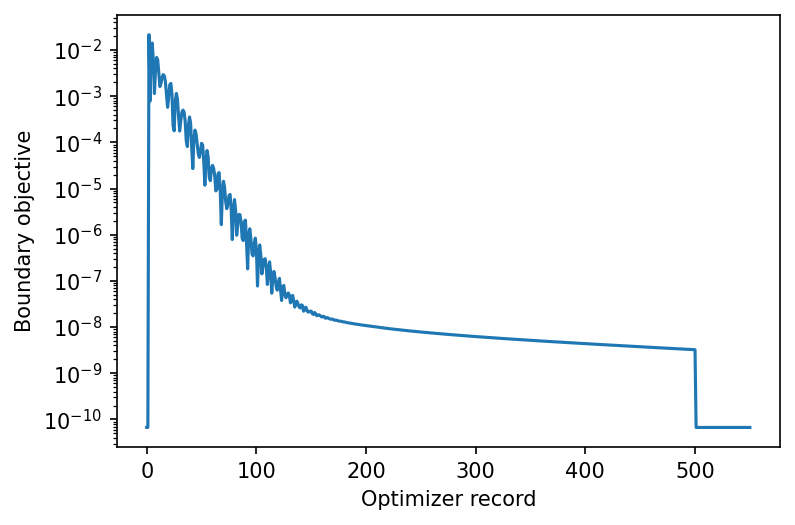

In [5]:
if torch is not None:
    class KMPikfnnCrackModel(torch.nn.Module):
        def __init__(self):
            super().__init__()
            self.theta = torch.nn.Parameter(torch.zeros((n_unknowns,1),device=device))
            self.register_buffer("col_scale",torch.as_tensor(col_scale[:,None],device=device))
        def coeffs(self):
            return self.theta/self.col_scale
    model = KMPikfnnCrackModel().to(device)
else:
    model = None


def train_model():
    started = time.perf_counter()
    if torch is None:
        print("SciPy SVD used; Adam/L-BFGS were NOT run.")
        return theta_ls.copy(), [numpy_objective(theta_ls)], "SciPy SVD (no PyTorch)"
    At = torch.as_tensor(A,device=device)
    bt = torch.as_tensor(rhs,device=device)
    def objective():
        return torch.sum((At@model.theta-bt)**2)+cfg["lambda_reg"]*torch.mean(model.theta[:-1]**2)
    with torch.no_grad():
        model.theta.zero_()
        if cfg["ls_warm_start"]:
            model.theta.copy_(torch.as_tensor(theta_ls,device=device))
    best_loss = objective().item()
    best_theta = model.theta.detach().clone()
    origin = "SVD initialization" if cfg["ls_warm_start"] else "zero initialization"
    history = [best_loss]
    def record(label):
        nonlocal best_loss,best_theta,origin
        value = objective().item()
        history.append(value)
        if value < best_loss:
            best_loss,best_theta,origin = value,model.theta.detach().clone(),label
        return value
    if cfg["adam_steps"]:
        opt = torch.optim.Adam(model.parameters(),lr=cfg["adam_lr"])
        for epoch in range(cfg["adam_steps"]):
            opt.zero_grad(); loss = objective(); loss.backward(); opt.step()
            value = record(f"Adam {epoch+1}")
            if epoch == 0 or (epoch+1)%100 == 0:
                print(f"Adam {epoch+1}: loss={value:.3e}, KII={model.coeffs()[-1,0].item():.9f}")
    with torch.no_grad(): model.theta.copy_(best_theta)
    if cfg["lbfgs_epochs"]:
        opt = torch.optim.LBFGS(model.parameters(),lr=1.,max_iter=cfg["lbfgs_max_iter"],
                               max_eval=cfg["lbfgs_max_iter"]+10,history_size=100,
                               tolerance_grad=1e-12,tolerance_change=1e-14,line_search_fn="strong_wolfe")
        for epoch in range(cfg["lbfgs_epochs"]):
            def closure():
                opt.zero_grad(); loss = objective(); loss.backward(); return loss
            opt.step(closure)
            value = record(f"L-BFGS {epoch+1}")
            if epoch == 0 or (epoch+1)%10 == 0:
                print(f"LBFGS {epoch+1}: loss={value:.3e}, KII={model.coeffs()[-1,0].item():.9f}")
    with torch.no_grad(): model.theta.copy_(best_theta)
    print(f"Restored best coefficients: {origin}; time={time.perf_counter()-started:.2f}s")
    return best_theta.cpu().numpy().copy(), history, origin

theta_final, loss_history, best_origin = train_model()
coefficients = theta_final/col_scale[:,None]
KII_pred = float(coefficients[-1,0])
rel_err = abs(KII_pred-KII_REF)/abs(KII_REF)
print(f"KII predicted: {KII_pred:.10f}")
print(f"KII benchmark approximation: {KII_REF:.10f}")
print(f"Relative difference: {rel_err:.6%}")
print("Best coefficient origin:",best_origin)
print("Regularized objective:",numpy_objective(theta_final))
if len(loss_history)>1:
    fig,ax = plt.subplots(figsize=(5.4,3.6),dpi=150)
    ax.semilogy(loss_history);ax.set_xlabel("Optimizer record");ax.set_ylabel("Boundary objective")
    fig.tight_layout();maybe_savefig(fig,"loss.png");plt.show()

## 独立配点与裂尖提取核查
在新的边界点检查残差。裂尖前方以 $\sqrt{2\pi r}\sigma_{xy}$ 检查 $K_{II}$；裂面切向位移采用含常数项的 $\sqrt r$ 拟合，避免微小平移残差经 $1/\sqrt r$ 放大。两种提取均不使用首阶系数作为拟合目标。

Independent boundary RMS (original, unweighted units):
  top       syy: 2.666e-08
  top       sxy: 3.294e-08
  right     sxx: 4.024e-07
  right     sxy: 4.021e-07
  left      uy : 1.825e-08
  left      sxx: 4.730e-07
  crack     syy: 7.744e-07
  crack     sxy: 2.599e-06
  ligament  ux : 5.262e-07
  ligament  syy: 2.931e-07
KII coefficient:             2.1317503253
KII ahead stress at r/a=1e-6:2.1317503531
KII upper-face sqrt(r) fit:  2.1317503251
Fitted face constant:        -1.392e-05


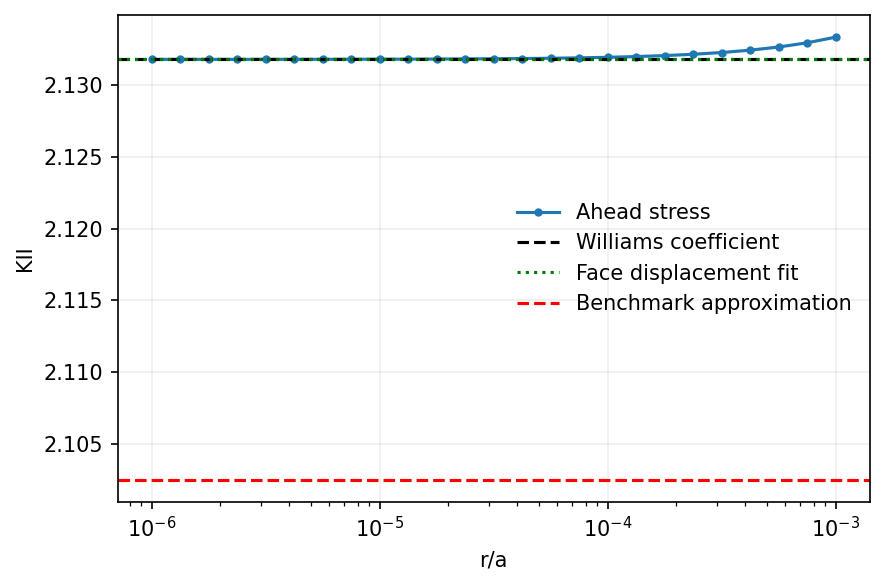

In [6]:
def evaluate_quantities(points, coeff=None, sources=None, batch_size=1500):
    points = np.asarray(points,dtype=np.complex128).reshape(-1)
    coeff = coefficients if coeff is None else np.asarray(coeff).reshape(-1,1)
    outs = {q:[] for q in QUANTITIES}
    for start in range(0,len(points),batch_size):
        bm = build_basis_columns(points[start:start+batch_size],sources)
        for q in QUANTITIES: outs[q].append((bm[q]@coeff).ravel())
    return {q:np.concatenate(parts) for q,parts in outs.items()}

validation_points = generate_boundary_points(
    {"n_top":177,"n_side":173,"n_crack":151,"n_ligament":149},midpoint=True)
validation_fields = {g:evaluate_quantities(z) for g,z in validation_points.items()}
print("Independent boundary RMS (original, unweighted units):")
for g,q,target,key in BOUNDARY_BLOCKS:
    rms = np.sqrt(np.mean((validation_fields[g][q]-target)**2))
    print(f"  {g:9s} {q:3s}: {rms:.3e}")

r_check = a*np.geomspace(1e-6,1e-3,25)
fa = evaluate_quantities(a+r_check+0j)
ff = evaluate_quantities(a-r_check+0j)
kii_stress = np.sqrt(2*np.pi*r_check)*fa["sxy"]
t = np.sqrt(r_check/a)
# ux = c0+c1*sqrt(r/a)+c2*(r/a)+...; c1 determines KII.
V = np.column_stack([t**j for j in range(5)])
fit = scipy_lstsq(V,ff["ux"],cond=1e-13,lapack_driver="gelsd")[0]
kii_displacement = 2*mu/(kappa+1)*np.sqrt(2*np.pi/a)*fit[1]
print(f"KII coefficient:             {KII_pred:.10f}")
print(f"KII ahead stress at r/a=1e-6:{kii_stress[0]:.10f}")
print(f"KII upper-face sqrt(r) fit:  {kii_displacement:.10f}")
print(f"Fitted face constant:        {fit[0]:.3e}")
fig,ax = plt.subplots(figsize=(6,4),dpi=150)
ax.semilogx(r_check/a,kii_stress,"o-",ms=3,label="Ahead stress")
ax.axhline(KII_pred,color="black",ls="--",label="Williams coefficient")
ax.axhline(kii_displacement,color="green",ls=":",label="Face displacement fit")
ax.axhline(KII_REF,color="red",ls="--",label="Benchmark approximation")
ax.set_xlabel("r/a");ax.set_ylabel("KII");ax.legend(frameon=False);ax.grid(alpha=.2)
fig.tight_layout();maybe_savefig(fig,"sif_checks.png");plt.show()

## 外部源点数量收敛检查（可选）
此检查只改变外部源点数量，保留几何、边界权重、配点与富集阶数。采用 SVD 求解相同目标，不重新执行优化器。该检查用于识别离散误差，不按参考误差挑选源点数。

In [7]:
def check_source_convergence(counts=(48,64,80)):
    results=[]
    print("n/side | sources | KII | objective | difference from benchmark")
    for n in counts:
        sources = generate_source_points(n)
        _,aa,bb,ss = assemble_system(sources=sources)
        tt,info = solve_same_objective_ls(aa,bb)
        kval = float(tt[-1,0]/ss[-1])
        row=dict(n_side=int(n),sources=len(sources),KII=kval,objective=info["objective"])
        results.append(row)
        print(f"{n:6d} | {len(sources):7d} | {kval:.10f} | {info['objective']:.3e} | {abs(kval-KII_REF)/abs(KII_REF):.4%}")
    return results

# Uncomment when needed; does not alter the trained model.
# convergence_results = check_source_convergence()

## 场图
裂尖本身不参与求值，绘图时遮盖小范围奇异点。默认显示三幅应力场及两幅位移场。

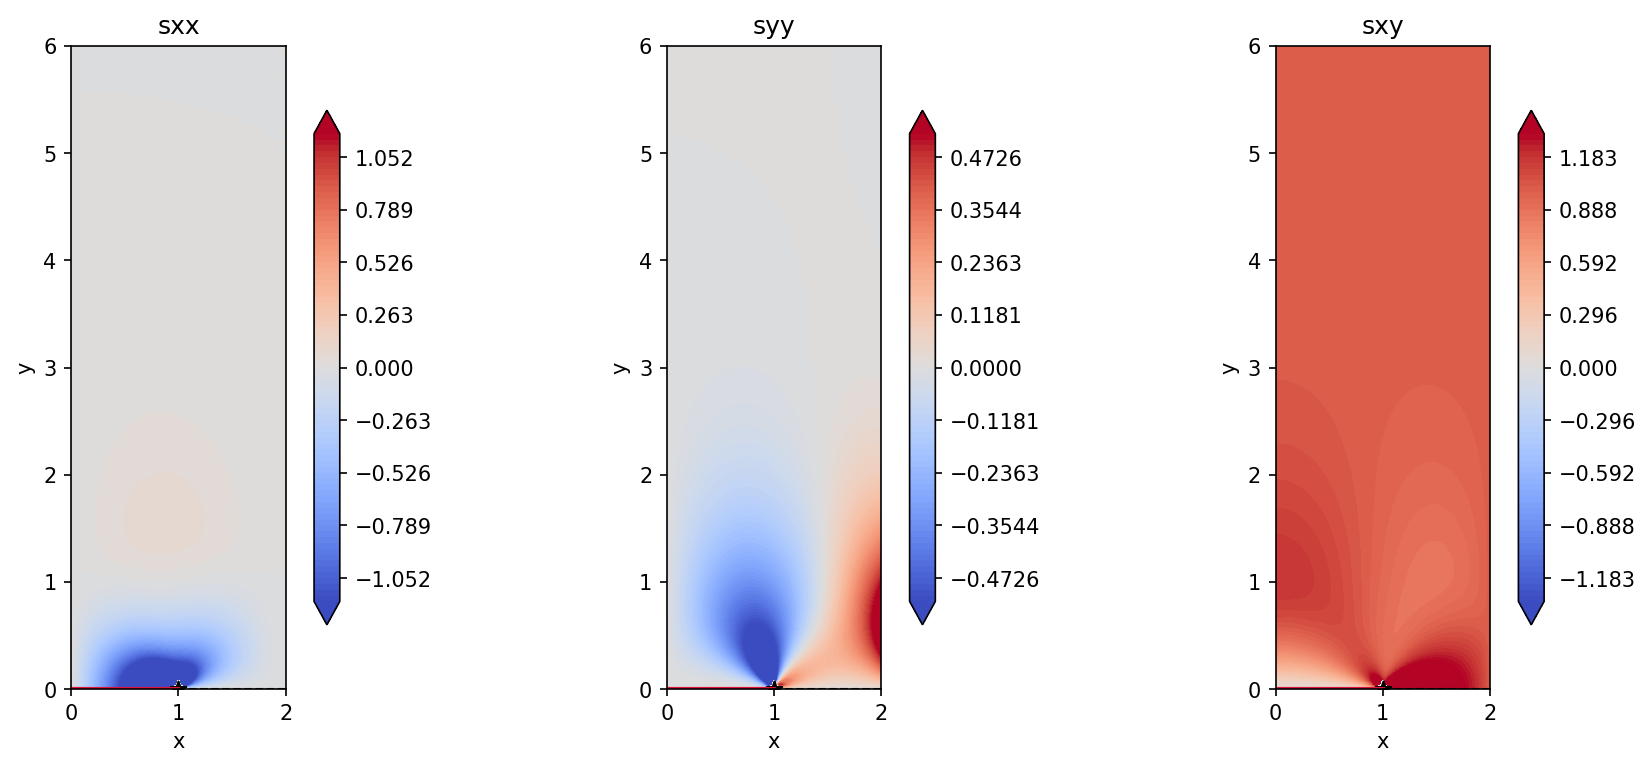

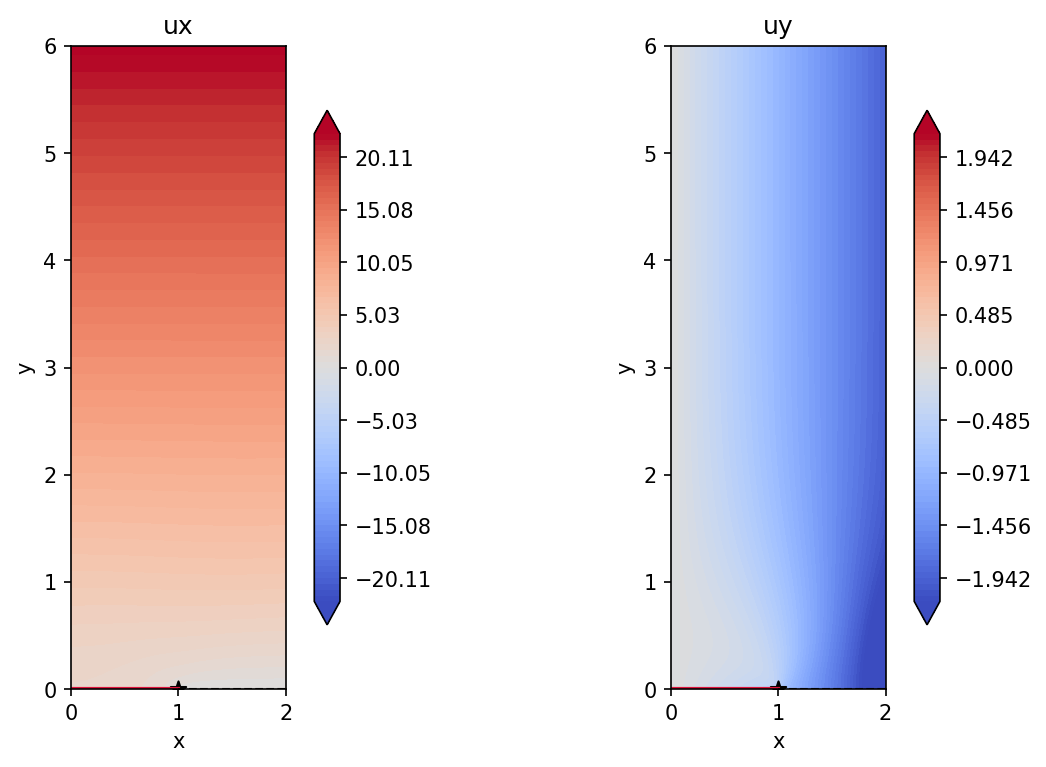

In [8]:
x_plot = np.linspace(0,b,cfg["nx_plot"])
y_plot = np.linspace(0,h,cfg["ny_plot"])
X,Y = np.meshgrid(x_plot,y_plot,indexing="xy")
z_grid = (X+1j*Y).ravel()
safe = np.abs(z_grid-a)>1e-12*a
fields_safe = evaluate_quantities(z_grid[safe])
fields={}
for q,values in fields_safe.items():
    assembled=np.full(len(z_grid),np.nan)
    assembled[safe]=values
    fields[q]=assembled.reshape(X.shape)
mask = np.hypot(X-a,Y)<0.05*a
for quantities,filename in [(("sxx","syy","sxy"),"stresses.png"),(("ux","uy"),"displacements.png")]:
    fig,axes=plt.subplots(1,len(quantities),figsize=(4*len(quantities),5),dpi=150,constrained_layout=True)
    for ax,q in zip(np.atleast_1d(axes),quantities):
        data=fields[q].copy()
        if q.startswith("s"):data[mask]=np.nan
        vmax=max(float(np.nanpercentile(np.abs(data),98.5)),1e-12)
        # Explicit levels ensure color normalization really clips at +/-vmax.
        im=ax.contourf(X,Y,data,levels=np.linspace(-vmax,vmax,81),cmap="coolwarm",extend="both")
        ax.plot([0,a],[0,0],color="crimson",lw=2)
        ax.plot([a,b],[0,0],"k--",lw=1)
        ax.scatter([a],[0],marker="*",s=60,color="black")
        ax.set_aspect("equal");ax.set_title(q);ax.set_xlabel("x");ax.set_ylabel("y")
        fig.colorbar(im,ax=ax,shrink=.8)
    maybe_savefig(fig,filename);plt.show()

if cfg["save_outputs"]:
    folder=Path(cfg["output_dir"]);folder.mkdir(parents=True,exist_ok=True)
    np.savez(folder/"coefficients_and_checks.npz",coefficients=coefficients,sources=src_pts,
             r=r_check,kii_stress=kii_stress,kii_displacement=kii_displacement,
             kii_pred=KII_pred,kii_reference=KII_REF,loss_history=np.asarray(loss_history))

参考核查：Zhou et al., *Transfer-learned Kolosov–Muskhelishvili Informed Neural Networks for Fracture Mechanics*, [arXiv:2601.00491](https://arxiv.org/html/2601.00491v1)，式 (27) 的二型辅助位移角函数支持这里的 $u_y$ 符号，式 (43) 给出原程序采用的参考公式。求解采用本 notebook 自洽的 KM 公式，不直接复制文献中其他公式的符号。